<a href="https://colab.research.google.com/github/JuCaRiCo/202602-AnaliticaDescriptivaPredictiva/blob/main/Semana13_ClasesNoBalanceadasDataLeakageSVM_271760.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Práctica: Ejercicios sobre Clases No Balanceadas, Data Leakage (Pipeline) y SVM**

**Materia**: Programacion para analítica descriptiva y predictiva

**Alumno**: Juan Carlos Rivera Cordova

**Matricula**: 271760

# **1. Análisis Exploratorio de Datos (AED) - Para esta actividad revisa el Notebook que està en Teams en la Sesion 27 y que se llama DataLeakage_ClassImbalance.ipynb**

Realizar:

- Un diagrama de barras mostrando la distribucion de las clases.
- Diagramas de densidad KDE para los atributos 5 y 13.
- Un análisis breve sobre el nivel de desbalance presente en el conjunto de datos.

***NOTA: No logre encontrar el notebook mencionado***

**Cargar Librerias**

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, make_scorer, precision_score, recall_score, f1_score, accuracy_score, roc_auc_score

from imblearn.combine import SMOTEENN
from imblearn.under_sampling import OneSidedSelection
from imblearn.pipeline import Pipeline as ImbPipeline



**Cargar archivo**

In [26]:
#Cargar archivo
df = pd.read_csv('compustat.csv')
df.head()

,idx,at0,at1,at2,at3,at4,at5,at6,at7,at8,...,at11,at12,at13,at14,at15,at16,at17,at18,at19,label
0,0,0.076753,0.066548,0.132170,4.257882,0.771988,0.669344,0.076278,2.898450,6.081867,...,2.052378,0.372113,0.322636,0.250182,1.153351,0.451476,0.590680,0.512143,0.076278,0
1,1,0.097633,0.087736,0.162879,4.141787,0.781934,0.702665,0.082633,2.947445,6.272092,...,1.968984,0.371728,0.334043,0.231646,1.112813,0.409376,0.593143,0.533012,0.056273,0
2,2,0.025683,0.022020,0.152882,3.140505,0.698522,0.598883,0.097905,2.971928,6.508112,...,1.374306,0.305678,0.262075,0.220100,1.166375,0.487141,0.476098,0.408186,0.050251,0
3,3,0.011354,0.008987,0.165670,2.927575,0.699374,0.553558,0.107831,2.955952,6.588417,...,1.173407,0.280317,0.221873,0.245524,1.263416,0.487903,0.460482,0.364474,0.047244,0
4,4,0.001675,0.001212,0.155509,3.120983,0.689971,0.499122,0.098458,2.896668,6.607998,...,1.069792,0.236504,0.171086,0.271291,1.382369,0.464594,0.468896,0.339197,0.042986,0


In [27]:
def print_cambio_seccion():
    print("\n","<"*70,"\n")

**Un diagrama de barras mostrando la distribucion de las clases.**

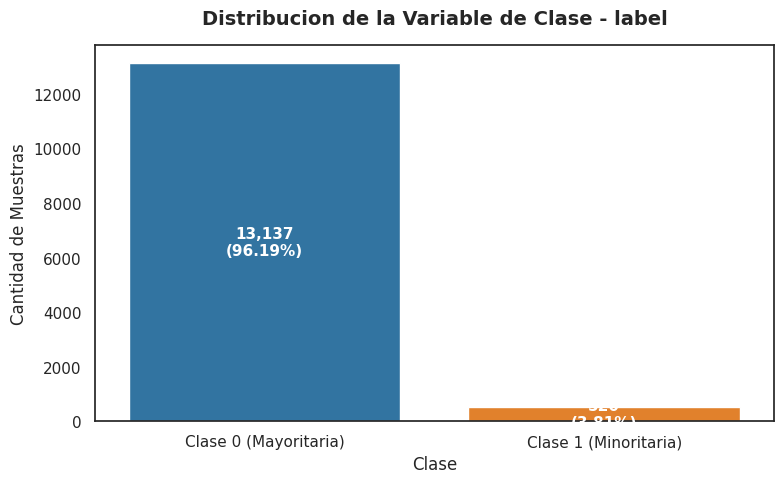

In [28]:
# Grafico de barras para la distribucion de clases
plt.rcParams.update({'font.size': 12})

plt.figure(figsize=(8, 5))
ax = sns.countplot(
    x='label',
    hue='label',
    data=df,
    palette=['#1f77b4', '#ff7f0e'],
    legend=False)
plt.title('Distribucion de la Variable de Clase - label', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Clase', fontsize=12)
plt.ylabel('Cantidad de Muestras', fontsize=12)
plt.xticks(ticks=[0, 1], labels=['Clase 0 (Mayoritaria)', 'Clase 1 (Minoritaria)'])

# Mostrar valores sobre las barras
for p in ax.patches:
    height = int(p.get_height())
    percentage = (height / len(df)) * 100
    ax.annotate(f'{height:,}\n({percentage:.2f}%)',
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', fontsize=11, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

**Diagramas de densidad KDE para los atributos 5 y 13.**

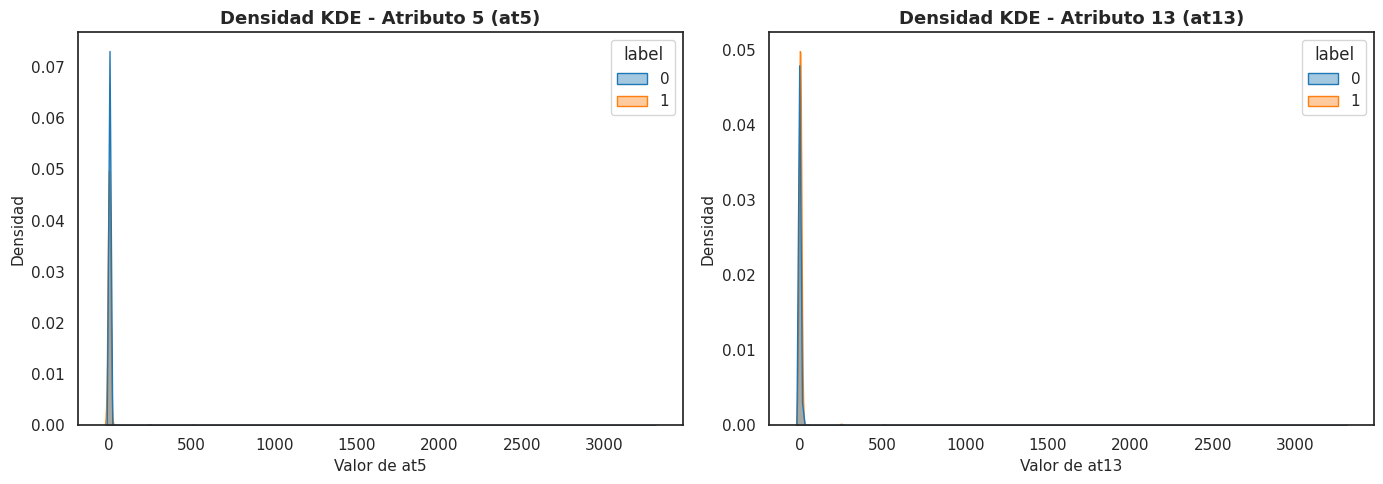

In [29]:
# Diagramas de densidad KDE para atributos 5 (at5) y 13 (at13) por clase
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Atributo 5 (at5)
sns.kdeplot(
    data=df,
    x='at5',
    hue='label',
    common_norm=False,
    palette=['#1f77b4', '#ff7f0e'],
    ax=axes[0],
    alpha=0.4,
    fill=True
)
axes[0].set_title('Densidad KDE - Atributo 5 (at5)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Valor de at5', fontsize=11)
axes[0].set_ylabel('Densidad', fontsize=11)

# Atributo 13 (at13)
sns.kdeplot(
    data=df,
    x='at13',
    hue='label',
    common_norm=False,
    palette=['#1f77b4', '#ff7f0e'],
    ax=axes[1],
    alpha=0.4,
    fill=True
)

axes[1].set_title('Densidad KDE - Atributo 13 (at13)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Valor de at13', fontsize=11)
axes[1].set_ylabel('Densidad', fontsize=11)

plt.tight_layout()
plt.show()

**Un análisis breve sobre el nivel de desbalance presente en el conjunto de datos.**

A partir de la visualizacion de las graficas, podemos identificar las siguientes caracteristicas:

1. **Nivel de desvalance severo**: La Clase 0, que es la mayoritaria, tiene un 96.19% de muestras, mientras que la Clase 1, la minoritaria, tiene solo un 3.81%, tiene un ratio de desvalance de aproximadamente 25.26 (13,137/520)
2. **Comportamiento de la densidad**: La densidad para los atributos at5 y at13, muestra una acumulacion fuerte concentrada en valores cercanas al cero, con una presencia de sesgo a la derecha y valores atipicos severos.

# **2. Modelo Base**

Entrenar un modelo baseline utilizando:

Pipeline([ <br/>
&nbsp;&nbsp;&nbsp;&nbsp;('scaler', StandardScaler()),<br/>
&nbsp;&nbsp;&nbsp;&nbsp;('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))<br/>
])

Este modelo deberá entrenarse sin aplicar métodos de tratamiento de desbalance y servirá como referencia para comparar los resultados posteriores.

REPORTE DE CLASIFICACION - MODELO BASE
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      3942
           1       1.00      0.01      0.01       156

    accuracy                           0.96      4098
   macro avg       0.98      0.50      0.50      4098
weighted avg       0.96      0.96      0.94      4098


 <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<< 



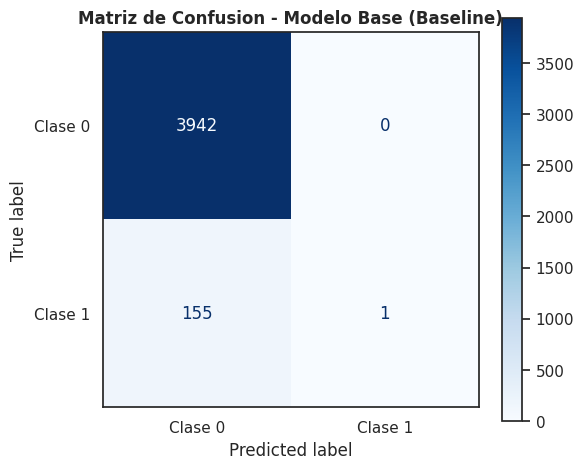

In [30]:
# 2. MODELO BASE

# Preparacion de variables predictoras X y variable objetivo y
X = df.drop(columns=['idx', 'label'])
y = df['label']

# Division en conjuntos de entrenamiento del 70% y prueba del 30% con estratificacion
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Definicion del Pipeline del Modelo Base sin tratamiento de desbalance
baseline_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
])

# Entrenamiento del modelo
baseline_pipeline.fit(X_train, y_train)

# Prediccion en el conjunto de prueba
y_pred_baseline = baseline_pipeline.predict(X_test)

# Evaluacion de resultados
print("REPORTE DE CLASIFICACION - MODELO BASE")
print(classification_report(y_test, y_pred_baseline, target_names=y.unique().astype(str)))
print_cambio_seccion()

# Visualizacion de la Matriz de Confusion
nombres_clases = ['Clase 0', 'Clase 1']

fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_baseline)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nombres_clases)
disp.plot(ax=ax, colorbar=True, cmap='Blues')
ax.set_title('Matriz de Confusion - Modelo Base (Baseline)', fontweight='bold')
ax.grid(False)
plt.tight_layout()
plt.show()


# **3. Tratamiento de Clases No Balanceadas**

Aplicar y comparar los siguientes métodos:
- SMOTEENN
- One-Sided Selection

Para cada método:
- Mostrar la nueva distribucion de clases después del balanceo.
- Entrenar nuevamente el modelo SVM utilizando los datos balanceados.

In [31]:
# 3. TRATAMIENTO DE CLASES NO BALANCEADAS

# Cargamos nuevamente los datos
X = df.drop(columns=['idx', 'label'])
y = df['label']

# Division en conjuntos de entrenamiento del 70% y prueba del 30% con estratificacion
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Escalamiento de datos (Fit en Train, Transform en Train y Test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Distribucion original en Entrenamiento: {y_train.value_counts().to_dict()}")

Distribucion original en Entrenamiento: {0: 9195, 1: 364}


**Metodo SMOTEENN**

Nueva distribucion de clases (SMOTEENN - Train):
  - Clase 0: 8,154 muestras
  - Clase 1: 9,178 muestras

 <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<< 


Reporte de Clasificacion - SVM + SMOTEENN:
              precision    recall  f1-score   support

           0     0.9915    0.7991    0.8850      3942
           1     0.1401    0.8269    0.2396       156

    accuracy                         0.8001      4098
   macro avg     0.5658    0.8130    0.5623      4098
weighted avg     0.9591    0.8001    0.8604      4098


 <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<< 



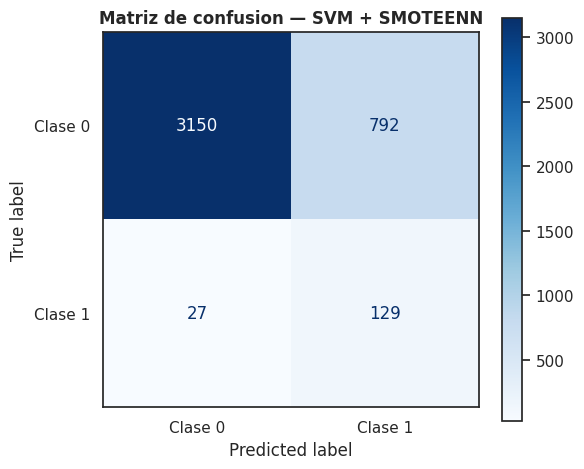

In [32]:
# Metodo SMOTEENN
# Aplicar SMOTEENN unicamente sobre el conjunto de entrenamiento escalado
smoteenn = SMOTEENN(random_state=42)
X_train_res_sm, y_train_res_sm = smoteenn.fit_resample(X_train_scaled, y_train)

# Mostrar la nueva distribucion de clases
dist_smoteenn = pd.Series(y_train_res_sm).value_counts()
print(f"Nueva distribucion de clases (SMOTEENN - Train):")
print(f"  - Clase 0: {dist_smoteenn[0]:,} muestras")
print(f"  - Clase 1: {dist_smoteenn[1]:,} muestras")

# Entrenar SVM con los datos balanceados por SMOTEENN
svm_smoteenn = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_smoteenn.fit(X_train_res_sm, y_train_res_sm)

# Prediccion en conjunto de prueba
y_pred_smoteenn = svm_smoteenn.predict(X_test_scaled)

print_cambio_seccion()
# Evaluacion de resultados
print("\nReporte de Clasificacion - SVM + SMOTEENN:")
print(classification_report(y_test, y_pred_smoteenn, digits=4))
print_cambio_seccion()

# Matriz de confusion
fig, ax = plt.subplots(figsize=(6, 5))
cm_sm = confusion_matrix(y_test, y_pred_smoteenn)
disp_sm = ConfusionMatrixDisplay(confusion_matrix=cm_sm, display_labels=nombres_clases)
disp_sm.plot(ax=ax, colorbar=True, cmap='Blues')
ax.grid(False)
ax.set_title('Matriz de confusion — SVM + SMOTEENN', fontweight='bold')
plt.tight_layout()
plt.show()

**Meetodo One-Sided Selection**

Nueva distribucion de clases (One-Sided Selection - Train):
  - Clase 0: 9,116 muestras
  - Clase 1: 364 muestras

 <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<< 


Reporte de Clasificacion - SVM + One-Sided Selection:
              precision    recall  f1-score   support

           0     0.9622    1.0000    0.9807      3942
           1     1.0000    0.0064    0.0127       156

    accuracy                         0.9622      4098
   macro avg     0.9811    0.5032    0.4967      4098
weighted avg     0.9636    0.9622    0.9439      4098


 <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<< 



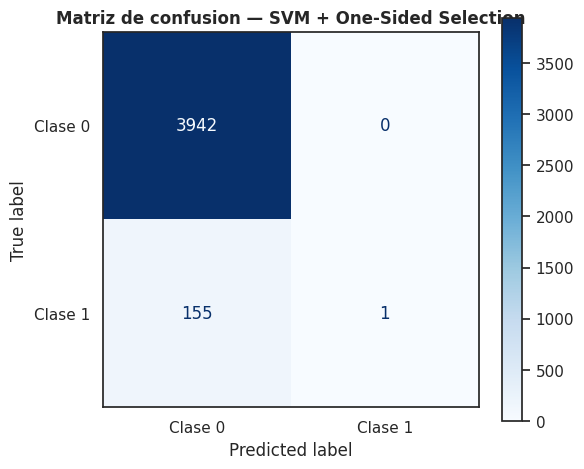

In [33]:
# Metodo One-Sided Selection (OSS - Submuestreo de la clase mayoritaria)
# Aplicar One-Sided Selection unicamente sobre el conjunto de entrenamiento escalado

oss = OneSidedSelection(random_state=42)
X_train_res_oss, y_train_res_oss = oss.fit_resample(X_train_scaled, y_train)

# Mostrar la nueva distribucion de clases
dist_oss = pd.Series(y_train_res_oss).value_counts()
print(f"Nueva distribucion de clases (One-Sided Selection - Train):")
print(f"  - Clase 0: {dist_oss[0]:,} muestras")
print(f"  - Clase 1: {dist_oss[1]:,} muestras")

# Entrenar SVM con los datos filtrados por OSS
svm_oss = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_oss.fit(X_train_res_oss, y_train_res_oss)

# Prediccion en conjunto de prueba
y_pred_oss = svm_oss.predict(X_test_scaled)

print_cambio_seccion()
# Evaluacion de resultados
print("\nReporte de Clasificacion - SVM + One-Sided Selection:")
print(classification_report(y_test, y_pred_oss, digits=4))

print_cambio_seccion()
# Matriz de confusion
fig, ax = plt.subplots(figsize=(6, 5))
cm_oss = confusion_matrix(y_test, y_pred_oss)
disp_oss = ConfusionMatrixDisplay(confusion_matrix=cm_oss, display_labels=nombres_clases)
disp_oss.plot(ax=ax, colorbar=True, cmap='Blues')
ax.grid(False)
ax.set_title('Matriz de confusion — SVM + One-Sided Selection', fontweight='bold')
plt.tight_layout()
plt.show()

# **4. Entrenamiento y Evaluacion del Modelo**
- Utilizar validacion cruzada estratificada de 5 particiones.
- Implementar el flujo de trabajo utilizando Pipeline para evitar data leakage.
- Incorporar escalado de datos dentro del Pipeline.
- Utilizar SVM con kernel RBF.

In [34]:
# ENTRENAMIENTO Y EVALUACION DEL MODELO

# Nuevamente Preparacion de variables
X = df.drop(columns=['idx', 'label'])
y = df['label']

# Configuracion de Validacion Cruzada Estratificada de 5 particiones
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Definicion de metricas de evaluacion
scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, pos_label=1, zero_division=0),
    'recall': make_scorer(recall_score, pos_label=1, zero_division=0),
    'f1': make_scorer(f1_score, pos_label=1, zero_division=0),
    'roc_auc': 'roc_auc'
}

# Pipeline Baseline (Sin tratamiento de desbalance)
pipe_baseline = ImbPipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
])

# Pipeline SMOTEENN
pipe_smoteenn = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smoteenn', SMOTEENN(random_state=42)),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
])

# Pipeline One-Sided Selection (OSS)
pipe_oss = ImbPipeline([
    ('scaler', StandardScaler()),
    ('oss', OneSidedSelection(random_state=42)),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
])

# Ejecucion de Validacion Cruzada (5-Fold Stratified CV)
cv_results_base = cross_validate(pipe_baseline, X, y, cv=skf, scoring=scoring, n_jobs=-1)
cv_results_smoteenn = cross_validate(pipe_smoteenn, X, y, cv=skf, scoring=scoring, n_jobs=-1)
cv_results_oss = cross_validate(pipe_oss, X, y, cv=skf, scoring=scoring, n_jobs=-1)

# Consolidación de Resultados Promedio
df_cv_results = pd.DataFrame({
    'Modelo / Estrategia': [
        'SVM Baseline (Sin Tratamiento)',
        'SVM + SMOTEENN (Híbrido)',
        'SVM + One-Sided Selection (OSS)'
    ],
    'Accuracy Promedio': [
        cv_results_base['test_accuracy'].mean(),
        cv_results_smoteenn['test_accuracy'].mean(),
        cv_results_oss['test_accuracy'].mean()
    ],
    'Precision (Clase 1)': [
        cv_results_base['test_precision'].mean(),
        cv_results_smoteenn['test_precision'].mean(),
        cv_results_oss['test_precision'].mean()
    ],
    'Recall (Clase 1)': [
        cv_results_base['test_recall'].mean(),
        cv_results_smoteenn['test_recall'].mean(),
        cv_results_oss['test_recall'].mean()
    ],
    'F1-Score (Clase 1)': [
        cv_results_base['test_f1'].mean(),
        cv_results_smoteenn['test_f1'].mean(),
        cv_results_oss['test_f1'].mean()
    ],
    'ROC AUC Promedio': [
        cv_results_base['test_roc_auc'].mean(),
        cv_results_smoteenn['test_roc_auc'].mean(),
        cv_results_oss['test_roc_auc'].mean()
    ]
})

print_cambio_seccion()
print(" RESULTADOS DE VALIDACIÓN CRUZADA ESTRATIFICADA (5-FOLDS)")
print_cambio_seccion()
print(df_cv_results.to_string(index=False))


 <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<< 

 RESULTADOS DE VALIDACIÓN CRUZADA ESTRATIFICADA (5-FOLDS)

 <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<< 

            Modelo / Estrategia  Accuracy Promedio  Precision (Clase 1)  Recall (Clase 1)  F1-Score (Clase 1)  ROC AUC Promedio
 SVM Baseline (Sin Tratamiento)           0.962217             0.600000          0.007692            0.015166          0.818418
       SVM + SMOTEENN (Híbrido)           0.811159             0.143910          0.800000            0.243934          0.881556
SVM + One-Sided Selection (OSS)           0.962217             0.833333          0.011538            0.022679          0.823575


# **5. Evaluación de Resultados**
- Reportar y analizar al menos las siguientes métricas:
- Accuracy
- Precision
- Recall
- F1-score
- Matriz de confusión


Además:
- Comparar los resultados del modelo baseline contra los modelos balanceados.
- Generar una gráfica comparativa de métricas.
- Analizar si Accuracy es suficiente para evaluar el problema.

**Reportar y analizar al menos las siguientes métricas:**
- Accuracy
- Precision
- Recall
- F1-score

In [35]:
# Consolidación de Metricas en el Conjunto de Prueba (Hold-Out)

def calcular_metricas(y_true, y_pred, nombre_modelo):
    return {
        'Modelo': nombre_modelo,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (Clase 1)': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'Recall (Clase 1)': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'F1-score (Clase 1)': f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    }

# Calculo para cada modelo
m_base = calcular_metricas(y_test, y_pred_baseline, 'SVM Baseline')
m_smoteenn = calcular_metricas(y_test, y_pred_smoteenn, 'SVM + SMOTEENN')
m_oss = calcular_metricas(y_test, y_pred_oss, 'SVM + One-Sided Selection')

# creamos dataframe comparativo
df_resumen = pd.DataFrame([m_base, m_smoteenn, m_oss])

print_cambio_seccion()
print("TABLA COMPARATIVA DE MÉTRICAS EN EL CONJUNTO DE PRUEBA (TEST)")
print_cambio_seccion()
print(df_resumen.to_string(index=False))



 <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<< 

TABLA COMPARATIVA DE MÉTRICAS EN EL CONJUNTO DE PRUEBA (TEST)

 <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<< 

                   Modelo  Accuracy  Precision (Clase 1)  Recall (Clase 1)  F1-score (Clase 1)
             SVM Baseline  0.962177             1.000000          0.006410            0.012739
           SVM + SMOTEENN  0.800146             0.140065          0.826923            0.239554
SVM + One-Sided Selection  0.962177             1.000000          0.006410            0.012739


**Matriz de confusión**

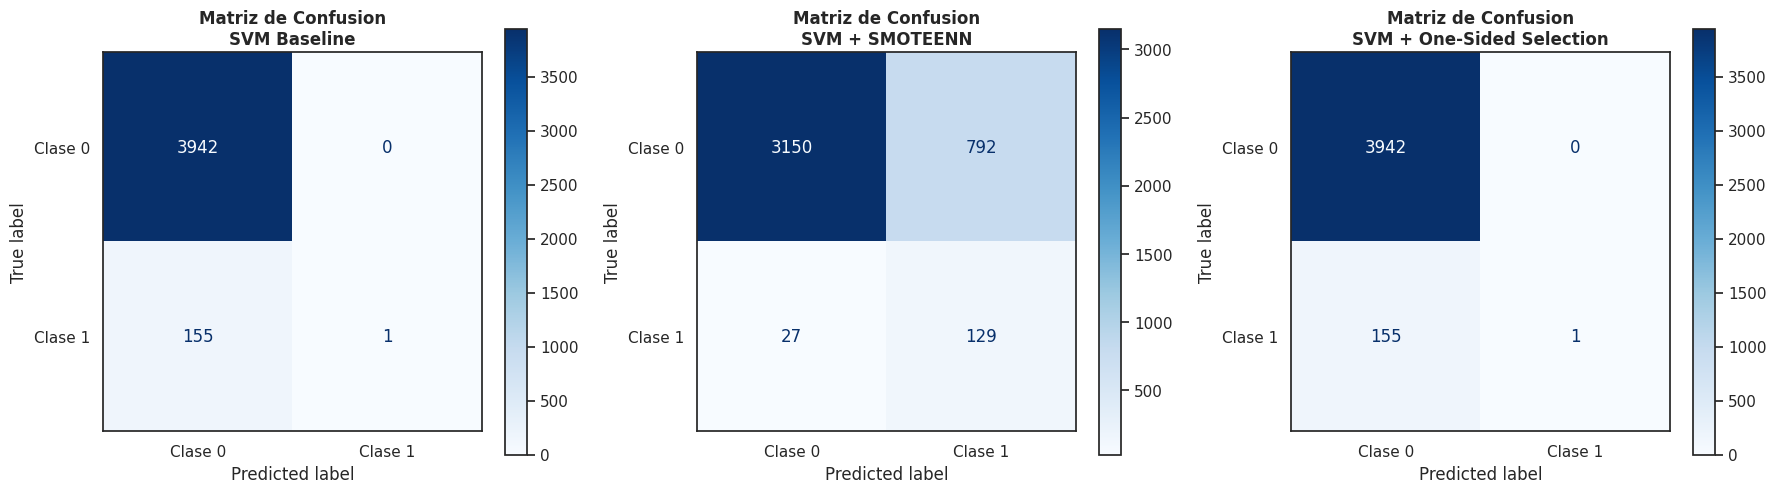

In [36]:
# Matriz de confusión

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

modelos_evaluados = [
    ('SVM Baseline', y_pred_baseline, axes[0]),
    ('SVM + SMOTEENN', y_pred_smoteenn, axes[1]),
    ('SVM + One-Sided Selection', y_pred_oss, axes[2])
]

for titulo, y_pred_m, ax in modelos_evaluados:
    cm = confusion_matrix(y_test, y_pred_m)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nombres_clases)
    disp.plot(ax=ax, colorbar=True, cmap='Blues')
    ax.grid(False)
    ax.set_title(f'Matriz de Confusion\n{titulo}', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

- **Comparar los resultados del modelo baseline contra los modelos balanceados.**
- **Generar una gráfica comparativa de métricas.**
- **Analizar si Accuracy es suficiente para evaluar el problema.**

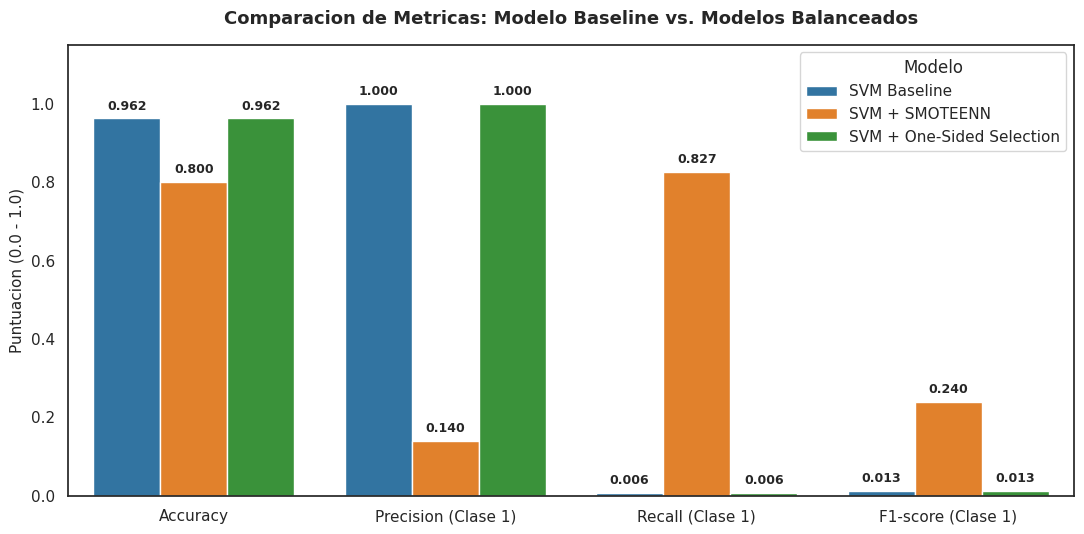

In [37]:
# Reestructurar datos para Seaborn
df_melted = df_resumen.melt(id_vars='Modelo', var_name='Métrica', value_name='Valor')

# 3. Construcción de la Gráfica Comparativa
sns.set_theme(style="white")
plt.figure(figsize=(11, 5.5))
ax = sns.barplot(
    data=df_melted,
    x='Métrica',
    y='Valor',
    hue='Modelo',
    palette=['#1f77b4', '#ff7f0e', '#2ca02c']
)

plt.title('Comparacion de Metricas: Modelo Baseline vs. Modelos Balanceados', fontweight='bold', fontsize=13, pad=15)
plt.ylim(0, 1.15)
plt.ylabel('Puntuacion (0.0 - 1.0)', fontsize=11)
plt.xlabel('')

# Agregar anotaciones numericas sobre cada barra
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.3f}',
                    (p.get_x() + p.get_width() / 2., height + 0.015),
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.legend(title='Modelo', loc='upper right')
plt.tight_layout()
plt.show()

**Comparacion de Resultados: Baseline vs. Técnicas de Balanceo**

Al analizar las metricas consolidadas en el conjunto de prueba, se logran apreciar diferencias entre el modelo base, y los modelos con tratamiento de desbalance.

1. **SVM Baseline (Sin Tratamiento):** Presenta un Accuracy de aproximadamente 96.2% (Optimo), pero un Recall casi inexistente de 0.64%. El modelo ignora la presencia de la Clase 1, si el modelo respondiera Clase cero para cualquier caso, estaria atinando el 96.2%, pero no significa que el modelo sea inteligente, en resumen, el modelo sufre un sesgo severo hacia la clase dominante, lo que demuestra la necesidad obligada de tecnicas de balanceo.
2. **SVM + SMOTEENN:** Este logra un incremento considerablemente alto, sobrepasando el 80% de Recall, permitiendo detectar una gran mayoria de los casos de interes, es decir la Clase 1. Si bien la precision se reduce a un 14%, el F1-Score sube considerablemente con respecto al Baseline, teniendo un equilibrio mayor.
3. **SVM + One-Sided Selection:** En este caso nos muestra que tiene una incapacidad de romper el desvalance, manteniendo las metricas iguales.

**Analizar si Accuracy es suficiente para evaluar el problema.**

No, como se ha visto en clase, el Accuracy es insuficiente y engañoso para evaluar el conjunto de datos. Con un desbalance de 3.81% sobre la Clase minoritaria, y el Accuracy de 96.22% da una sensacion de rendimiento alto, pero ignorando que el modelo no detecta la clase de interes.

En los escenarios con desbalance severo se debe priorizar el Recall, que tiene la sencibilidad para detectar la clase 1, el F1-Score que representa el equilibrio entre el Recall y Precision

# **6. Discusión y Conclusiones**

**Discutir**:
- **El impacto del desbalance sobre el desempeño del modelo.**
  
  Basados en el desvalance que hay entre clases, de 3.81% contra 96.19%, podemos ver que hay un sesgo hacia la clase dominante, esto lleva a que el algoritmo clasifique practicamente el 100% de instancias como clases mayoritaria. El hecho de que el Accuracy sea de 96.22% da una false sensacion de precision, pero con tan solo un 0.64% de Recall demuestra que la exactitud es una metrica inadecuada para toma de decisiones.

- **Las diferencias observadas entre SMOTEENN y One-Sided Selection.**

  Las dos tecnicas de balanceo muestran comportamientos totalmente diferentes.
  
  SMOTEENN logra romper eficazmente la insensibilidad del modelo SVM, aumentando el Recall hasta 82.69%, y alcanzando un F1-score de 24%.

  En cuanto al One-Sided Selection, podemos ver que es completamente ineficaz en este escenario, obteniendo resultados identicos a los de Baseline.

- **Qué método produjo los mejores resultados y por qué.**
  El metodo que produjo los mejores resultados funcionales fue SMOTEENN, tuvo una deteccion efectiva de la clase de interes, fue la unica tecnica capaz de rescatar el 82.69% de las muestras de la Clase 1.
  